# Dengue Outbreak Early-Warning for Colombo District, Sri Lanka
**Applied Machine Learning – Assignment 2**

## 1. Problem statement
Dengue is one of Sri Lanka's biggest public-health problems, and **Colombo district reports the
highest number of cases in the country** every year. Vector-control actions (fogging, breeding-site
clean-up campaigns, school awareness programmes, preparing hospital beds) take one to several weeks
to organise. If the Medical Officer of Health (MOH) knows **in advance** that the coming month will be a
high-dengue period, these resources can be deployed *before* the peak instead of after it.

**ML task (binary classification):**
> Using only information available at the end of the current week (recent case counts, recent weather,
> time of year), predict whether the **average weekly dengue cases over the next 4 weeks** will exceed
> the *high-risk threshold* (75th percentile of the training period).

**Why 4-week average and not next week's count?** Weekly notifications are very noisy (e.g. 41 cases one
week, 231 the next) because of reporting delays and batching. A 4-week window matches the planning
horizon of a vector-control campaign and removes most of the reporting noise.

**Proposed algorithm: Extra Trees (Extremely Randomized Trees, Geurts, Ernst & Wehenkel, 2006).** It was
not covered in the lectures. It is compared against the algorithms that were taught (logistic regression,
KNN, decision tree, Random Forest, AdaBoost, Gradient Boosting, XGBoost, LightGBM, CatBoost, stacking)
and a naive rule, all under time-aware validation. Section 5.2 explains why it was selected and how it
differs from the standard models.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.ensemble import (AdaBoostClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              RandomForestClassifier, StackingClassifier)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, average_precision_score,
                             balanced_accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT)  # so parallel CV workers can import src/
from src.data_prep import (CASE_FEATURES, HORIZON, SEASON_FEATURES, WEATHER_COLS, WEATHER_FEATURES,
                           ColumnSelector, QuantileClipper, clean, load_raw, make_features)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
(ROOT / "models").mkdir(exist_ok=True)


def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 2. Data
**Source:** weekly notified dengue cases for Colombo district from the *Weekly Epidemiological Reports*
of the **Epidemiology Unit, Ministry of Health, Sri Lanka**, combined with weekly weather for Colombo.
The combined dataset was published by Talagala (University of Sri Jayewardenepura) as the R package
`colmozzie`; it was downloaded from the package's GitHub repository and converted to CSV.

| Column | Meaning | Unit |
|---|---|---|
| `Cases` | Notified dengue cases in Colombo district that week | count |
| `Year`, `Week` | ISO year and week number | – |
| `TEM` | Average temperature | °C |
| `TMAX` / `Tm` | Maximum / minimum temperature | °C |
| `SLP` | Atmospheric pressure at sea level | hPa |
| `H` | Average relative humidity | % |
| `PP` | Total rainfall / snowmelt | mm |
| `VV` | Average visibility | km |
| `V` / `VM` | Average / maximum sustained wind speed | km/h |

The dataset is small (279 weeks), which is typical of real public-health surveillance data.

In [2]:
raw = load_raw(ROOT / "data" / "raw" / "colombo_dengue_weather.csv")
print(raw.shape)
raw.head()

(279, 12)


,Cases,Year,Week,TEM,TMAX,Tm,SLP,H,PP,VV,V,VM
0,44,2009,1,27.300,32.7000,23.60,1010.7,68.0000,0.00,13.0000,11.1000,20.600
1,39,2009,2,26.400,29.7667,23.90,1010.7,78.6667,0.00,18.3333,5.8333,9.200
2,57,2009,3,27.140,32.0200,23.52,1012.58,67.0000,0.00,20.0000,6.1200,10.460
3,53,2009,4,26.800,31.0000,23.35,1009.9,68.0000,0.00,20.0000,7.1500,11.100
4,29,2009,5,26.775,30.0750,23.60,1010.1,78.0000,17.21,18.9750,3.2000,6.825


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279 entries, 0 to 278
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Cases   279 non-null    int64  
 1   Year    279 non-null    int64  
 2   Week    279 non-null    int64  
 3   TEM     279 non-null    float64
 4   TMAX    279 non-null    float64
 5   Tm      279 non-null    float64
 6   SLP     279 non-null    object 
 7   H       279 non-null    float64
 8   PP      279 non-null    float64
 9   VV      279 non-null    float64
 10  V       279 non-null    float64
 11  VM      279 non-null    float64
dtypes: float64(8), int64(3), object(1)
memory usage: 26.3+ KB


In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Cases,279.0,116.34,79.54,0.00,57.00,99.00,155.00,475.00
Year,279.0,2011.21,1.57,2009.00,2010.00,2011.00,2013.00,2014.00
Week,279.0,25.29,15.19,1.00,12.00,24.00,38.50,53.00
TEM,279.0,27.58,0.88,24.19,26.93,27.54,28.16,29.66
TMAX,279.0,30.82,0.86,27.31,30.21,30.74,31.38,33.71
Tm,279.0,24.90,1.29,20.83,23.95,24.71,26.03,27.84
H,279.0,79.79,4.22,62.00,78.34,79.86,82.14,90.29
PP,279.0,6.51,9.62,0.00,0.71,4.14,8.25,71.34
VV,279.0,19.47,0.90,10.94,19.37,19.66,19.96,20.29
V,279.0,5.11,1.75,0.85,3.79,4.91,6.35,14.39


## 3. Exploratory data analysis
### 3.1 Data-quality checks
Before modelling we checked whether every value is *plausible* — not only whether it is missing.

In [5]:
slp_numeric = pd.to_numeric(raw["SLP"], errors="coerce")
print("Non-numeric SLP values:", raw.loc[slp_numeric.isna(), ["Year", "Week", "SLP"]].to_dict("records"))

print("\nWeeks reporting 0 cases:")
print(raw.loc[raw["Cases"] == 0, ["Year", "Week", "Cases"]].to_string(index=False))

print("\nNumber of weeks per year:")
print(raw.groupby("Year")["Week"].agg(["count", "min", "max"]))

print("\nWeekly variability (std) of weather per year:")
print(raw.assign(SLP=slp_numeric).groupby("Year")[["TEM", "H", "PP", "V"]].std().round(3))

Non-numeric SLP values: [{'Year': 2009, 'Week': 50, 'SLP': '#DIV/0!'}]

Weeks reporting 0 cases:
 Year  Week  Cases
 2012    18      0
 2012    19      0
 2012    24      0
 2012    29      0
 2012    45      0

Number of weeks per year:
      count  min  max
Year                 
2009     52    1   53
2010     52    1   52
2011     52    1   52
2012     52    1   52
2013     50    1   52
2014     21    1   21

Weekly variability (std) of weather per year:
        TEM      H      PP      V
Year                             
2009  0.781  4.629   8.423  2.401
2010  0.965  5.042  14.707  1.627
2011  1.014  3.641   6.540  1.738
2012  0.883  4.208   6.968  1.351
2013  0.817  4.280  10.957  1.781
2014  0.035  0.212   0.311  0.124


**Findings**
1. **`SLP` contains an Excel error `#DIV/0!`** (2009 week 50), so the column was read as text.
2. **Five weeks in 2012 report 0 cases.** 2012 was a severe dengue year and the neighbouring weeks have
   60–200 cases, so these are *missing reports*, not real zeros. Treating them as 0 would teach the model
   something false.
3. **Weeks 37–38 of 2013 are missing** from the series.
4. **The 2014 weather is not real observations.** Its weekly standard deviation is ~25× smaller than in
   other years (e.g. temperature std 0.035 °C vs ~0.85 °C) and the values have long decimal tails: the
   dataset author filled them in. We therefore **only use data up to 2013 week 51**, where the weather was
   observed.

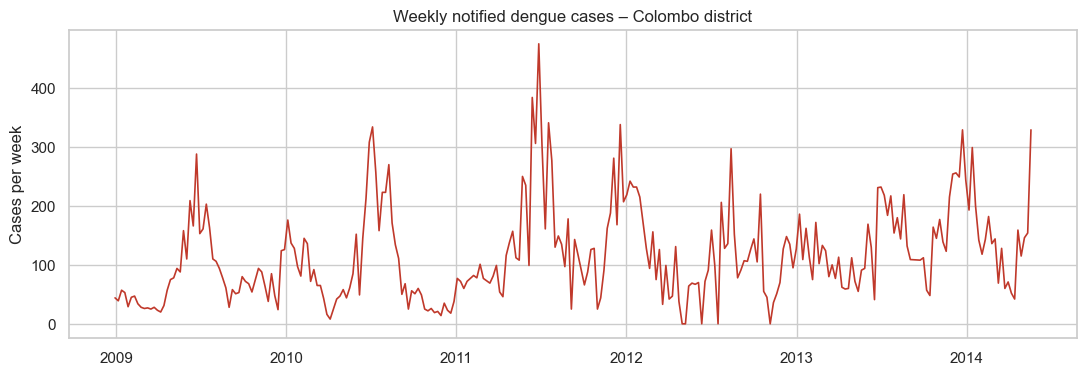

In [6]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(pd.to_datetime(raw["Year"].astype(str) + raw["Week"].astype(str).str.zfill(2) + "1",
                       format="%G%V%u"), raw["Cases"], color="#c0392b", lw=1.2)
ax.set_title("Weekly notified dengue cases – Colombo district")
ax.set_ylabel("Cases per week")
savefig("01_weekly_cases")
plt.show()

The series shows **two outbreak seasons per year** (around June–July after the south-west monsoon, and
around December–January after the north-east monsoon), a large outbreak in mid-2011, and strong
week-to-week noise.

Cleaned shape: (260, 12) | period: 2008-12-29 to 2013-12-16
Missing values after cleaning: 0


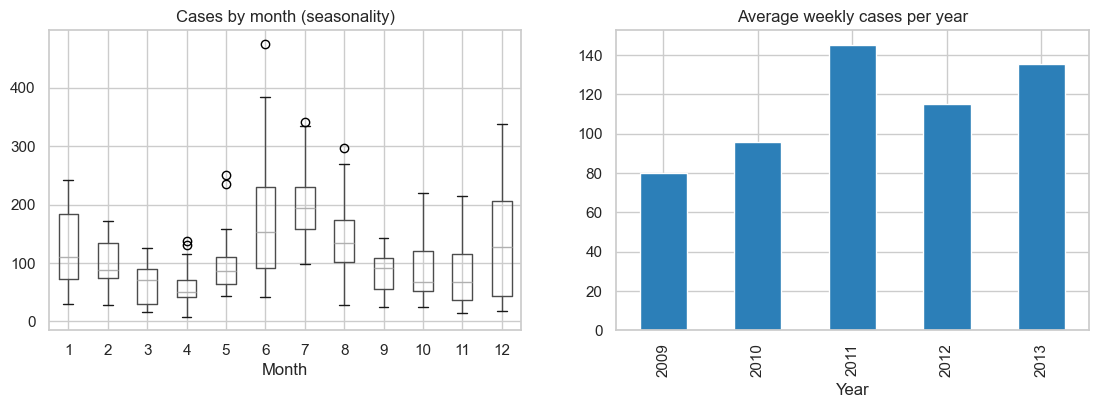

In [7]:
df = clean(raw)
print("Cleaned shape:", df.shape, "| period:", df.index.min().date(), "to", df.index.max().date())
print("Missing values after cleaning:", int(df.isna().sum().sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.assign(Month=df.index.month).boxplot(column="Cases", by="Month", ax=axes[0])
axes[0].set_title("Cases by month (seasonality)")
axes[0].set_xlabel("Month")
plt.suptitle("")
df.groupby("Year")["Cases"].mean().plot(kind="bar", ax=axes[1], color="#2c7fb8")
axes[1].set_title("Average weekly cases per year")
savefig("02_seasonality")
plt.show()

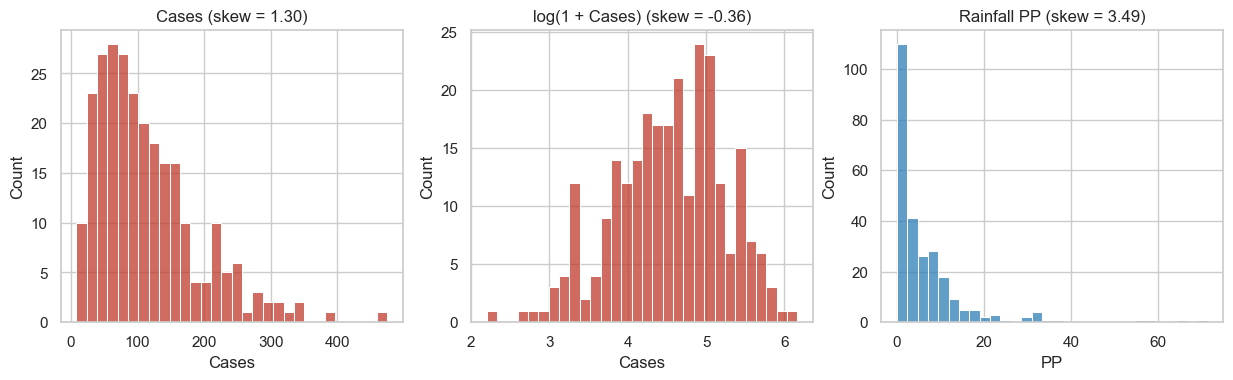

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(df["Cases"], bins=30, ax=axes[0], color="#c0392b")
axes[0].set_title(f"Cases (skew = {df['Cases'].skew():.2f})")
sns.histplot(np.log1p(df["Cases"]), bins=30, ax=axes[1], color="#c0392b")
axes[1].set_title(f"log(1 + Cases) (skew = {np.log1p(df['Cases']).skew():.2f})")
sns.histplot(df["PP"], bins=30, ax=axes[2], color="#2c7fb8")
axes[2].set_title(f"Rainfall PP (skew = {df['PP'].skew():.2f})")
savefig("03_distributions")
plt.show()

Case counts and especially rainfall are **right-skewed** with a few extreme values (outbreak weeks,
55–71 mm rain weeks). These are real events, so we do not delete them. Instead we
**log-transform** them, and in the model pipeline we **winsorise** (clip) features to the 1st–99th
percentile learned from the training data.

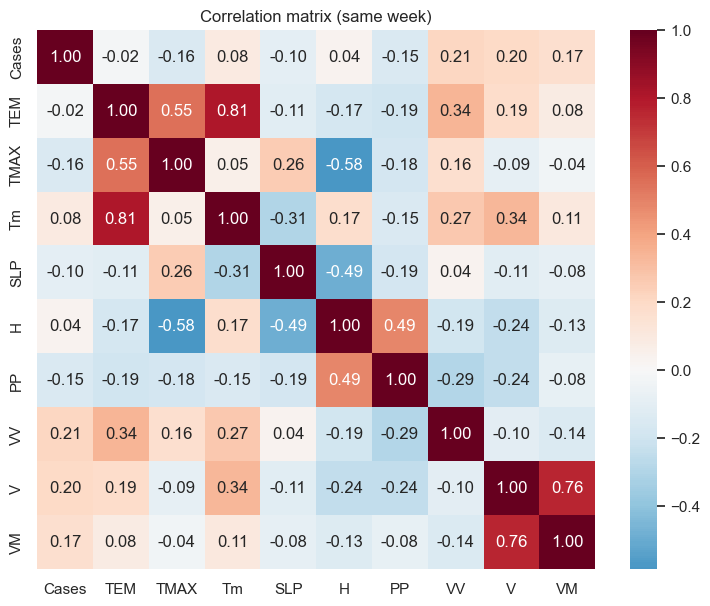

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[["Cases"] + WEATHER_COLS].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation matrix (same week)")
savefig("04_correlation")
plt.show()

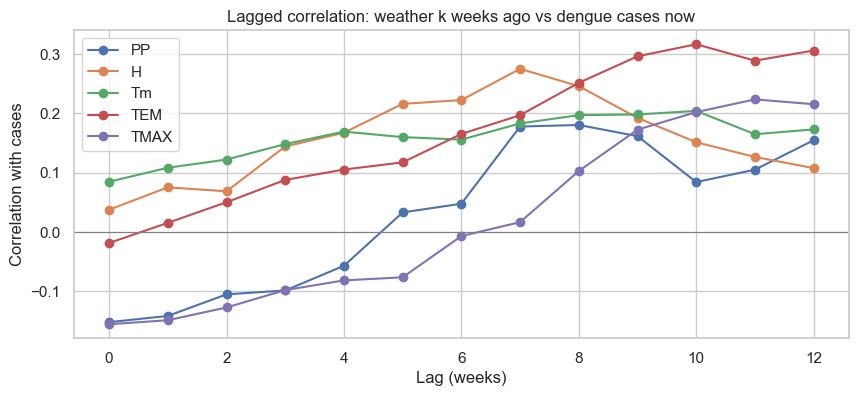

,PP,H,Tm,TEM,TMAX
0,-0.15,0.04,0.08,-0.02,-0.16
1,-0.14,0.08,0.11,0.02,-0.15
2,-0.11,0.07,0.12,0.05,-0.13
3,-0.10,0.14,0.15,0.09,-0.10
4,-0.06,0.17,0.17,0.11,-0.08
5,0.03,0.22,0.16,0.12,-0.08
6,0.05,0.22,0.16,0.17,-0.01
7,0.18,0.28,0.18,0.20,0.02
8,0.18,0.25,0.20,0.25,0.10
9,0.16,0.19,0.20,0.30,0.17


In [10]:
# Weather affects dengue with a delay (mosquito breeding + virus incubation),
# so we look at correlation between weather k weeks ago and cases now.
lags = range(0, 13)
lag_corr = pd.DataFrame({
    col: [df["Cases"].corr(df[col].shift(k)) for k in lags] for col in ["PP", "H", "Tm", "TEM", "TMAX"]
}, index=lags)
lag_corr.plot(marker="o", figsize=(10, 4))
plt.axhline(0, color="grey", lw=0.8)
plt.xlabel("Lag (weeks)")
plt.ylabel("Correlation with cases")
plt.title("Lagged correlation: weather k weeks ago vs dengue cases now")
savefig("05_lagged_correlation")
plt.show()
lag_corr.round(2)

Same-week correlations are weak, and rainfall is even slightly *negative* (heavy rain flushes larvae away).
Rainfall, humidity and temperature become positively correlated with cases **5–10 weeks later**, which
matches the transmission cycle (rain → breeding sites → adult mosquitoes → infection → symptoms). All
correlations stay below 0.32, so weather alone is a weak signal. This motivates **lagged weather windows**
(0–3 and 4–7 weeks ago) as *candidate* features, which are tested in section 4.3.

## 4. Pre-processing and feature engineering
| Step | What | Why |
|---|---|---|
| Type fix | `SLP` text → numeric | Excel `#DIV/0!` error |
| Missing values | False zeros and missing weeks → NaN → **linear interpolation in time** | A time series must stay continuous; interpolation uses neighbouring weeks |
| Unreliable data | Drop 2013-W52 and 2014 | Weather was imputed by the author, not observed |
| Transformation | `log(1+x)` of cases and rainfall | Reduces skew from outbreaks and heavy-rain weeks |
| Lag / rolling features | Case means over 2/4/8 weeks, 4-week trend, weather means 0–3 and 4–7 weeks ago | Uses only the past, never the future (no leakage) |
| Seasonality | sin/cos of week number | Week 52 and week 1 are neighbours |
| Outliers | Winsorise to 1st–99th percentile (in pipeline) | Limits influence of extreme weeks without deleting real events |
| Scaling | `StandardScaler` (in pipeline) | Needed by logistic regression and KNN baselines; harmless for trees |
| Imputation (pipeline) | `SimpleImputer(median)` | Safety net for missing inputs at inference time in the app |

In [11]:
table = make_features(df)
FEATURES = CASE_FEATURES + WEATHER_FEATURES + SEASON_FEATURES
table = table.dropna(subset=["future_mean_cases"])
print("Modelling table:", table.shape)
table[FEATURES + ["future_mean_cases"]].head()

Modelling table: (249, 18)


,cases_now,cases_mean2,cases_mean4,cases_mean8,cases_trend,PP_lag0_3,PP_lag4_7,H_lag0_3,H_lag4_7,Tm_lag0_3,Tm_lag4_7,TEM_lag0_3,TEM_lag4_7,week_sin,week_cos,future_mean_cases
date,,,,,,,,,,,,,,,,
2009-02-16,3.555348,3.713275,3.664097,3.775170,-0.222145,0.725493,0.000000,71.175000,70.416675,23.063750,23.59250,26.797500,26.91000,0.822984,0.568065,26.50
2009-02-23,3.367296,3.461322,3.655622,3.720249,-0.129254,0.131182,0.725493,71.496425,72.916675,23.442325,23.59250,27.057325,26.77875,0.885456,0.464723,26.50
2009-03-02,3.295837,3.331566,3.522420,3.671118,-0.297396,0.639989,0.725493,72.771425,71.375000,23.867325,23.36750,27.354825,26.89125,0.935016,0.354605,25.75
2009-03-09,3.332205,3.314021,3.387671,3.580089,-0.384835,0.994758,0.725493,76.429750,70.925000,24.443150,23.03250,27.632325,26.66625,0.970942,0.239316,24.00
2009-03-16,3.258097,3.295151,3.313358,3.488728,-0.350739,1.576648,0.725493,78.751175,71.175000,24.517250,23.06375,27.658225,26.79750,0.992709,0.120537,25.50


### 4.1 Train / test split (chronological) and target
* **Training:** 2009–2012. **Test (hold-out):** 2013, used **only once** at the end.
* A random split would leak information because neighbouring weeks are almost identical, so we split by time.
* **Purging:** the target of the last 4 training weeks of 2012 uses cases from January 2013. Those rows are
  removed from training so that no test-period information is used.
* **High-risk threshold** = 75th percentile of the training targets, computed on training data only.

In [12]:
TEST_START = pd.Timestamp("2012-12-31")  # ISO week 1 of 2013
purge_cutoff = TEST_START - pd.Timedelta(weeks=HORIZON)

train = table[table.index < purge_cutoff]
test = table[table.index >= TEST_START]

THRESHOLD = float(train["future_mean_cases"].quantile(0.75))
y_train = (train["future_mean_cases"] > THRESHOLD).astype(int)
y_test = (test["future_mean_cases"] > THRESHOLD).astype(int)
X_train, X_test = train[FEATURES], test[FEATURES]

print(f"High-risk threshold: > {THRESHOLD:.1f} cases/week (4-week average)")
print(f"Train: {len(train)} weeks ({train.index.min().date()} to {train.index.max().date()}), "
      f"high-risk = {y_train.mean():.0%}")
print(f"Test : {len(test)} weeks ({test.index.min().date()} to {test.index.max().date()}), "
      f"high-risk = {y_test.mean():.0%}")
print("\nHigh-risk weeks per training year:")
print(y_train.groupby(train["Year"]).agg(["sum", "count"]))

High-risk threshold: > 146.2 cases/week (4-week average)
Train: 198 weeks (2009-02-16 to 2012-11-26), high-risk = 25%
Test : 47 weeks (2012-12-31 to 2013-11-18), high-risk = 32%

High-risk weeks per training year:
      sum  count
Year            
2009    7     46
2010   10     52
2011   21     52
2012   12     48


### 4.2 Train / validation / test design (time-aware cross-validation)
* **Test set:** 2013, held out until the very end.
* **Validation sets:** two walk-forward folds inside 2009–2012, used for feature-set choice,
  hyper-parameter tuning and choosing the alert cut-off.

Hyper-parameters are tuned with **walk-forward (expanding-window) cross-validation** inside the
training period:
* Fold 1: train 2009–2010 → validate 2011
* Fold 2: train 2009–2011 → validate 2012

Each fold also purges the 4 weeks before the validation year. Normal k-fold CV would let the model
"see the future".

In [13]:
def walk_forward_folds(index, years=(2011, 2012), horizon=HORIZON):
    folds = []
    iso_year = pd.Series(index.isocalendar().year.values, index=index)
    for yr in years:
        val_start = index[iso_year.values == yr].min()
        tr_idx = np.where(index < val_start - pd.Timedelta(weeks=horizon))[0]
        va_idx = np.where(iso_year.values == yr)[0]
        folds.append((tr_idx, va_idx))
    return folds


CV = walk_forward_folds(X_train.index)
for i, (tr, va) in enumerate(CV, 1):
    print(f"Fold {i}: train {len(tr)} weeks, validate {len(va)} weeks, "
          f"val high-risk share = {y_train.iloc[va].mean():.0%}")

Fold 1: train 94 weeks, validate 52 weeks, val high-risk share = 40%
Fold 2: train 146 weeks, validate 48 weeks, val high-risk share = 25%


In [14]:
def make_pipeline(model, columns):
    return Pipeline([
        ("select", ColumnSelector(columns)),
        ("impute", SimpleImputer(strategy="median")),
        ("clip", QuantileClipper(0.01, 0.99)),
        ("scale", StandardScaler()),
        ("model", model),
    ])

### 4.3 Do the weather features help?
Before tuning, we check which **feature set** generalises better, using the same CV folds and a
reasonable random forest. Weather is the "obvious" driver of dengue, but with only ~200 training weeks,
8 extra weather features could just add noise.

In [15]:
feature_sets = {
    "cases + season": CASE_FEATURES + SEASON_FEATURES,
    "cases + season + weather": CASE_FEATURES + WEATHER_FEATURES + SEASON_FEATURES,
    "season + weather only": WEATHER_FEATURES + SEASON_FEATURES,
}
probe_models = {
    "RandomForest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05, random_state=SEED),
}
rows = []
for fs_name, cols in feature_sets.items():
    for m_name, m in probe_models.items():
        aucs = []
        for tr, va in CV:
            pipe = make_pipeline(clone(m), cols).fit(X_train.iloc[tr], y_train.iloc[tr])
            aucs.append(roc_auc_score(y_train.iloc[va], pipe.predict_proba(X_train.iloc[va])[:, 1]))
        rows.append({"feature set": fs_name, "model": m_name, "CV AUC fold 2011": aucs[0],
                     "CV AUC fold 2012": aucs[1], "mean CV AUC": np.mean(aucs)})
fs_results = pd.DataFrame(rows).round(3)
fs_results

,feature set,model,CV AUC fold 2011,CV AUC fold 2012,mean CV AUC
0,cases + season,RandomForest,0.879,0.884,0.882
1,cases + season,XGBoost,0.856,0.883,0.870
2,cases + season + weather,RandomForest,0.911,0.873,0.892
3,cases + season + weather,XGBoost,0.845,0.844,0.844
4,season + weather only,RandomForest,0.731,0.572,0.651
5,season + weather only,XGBoost,0.638,0.616,0.627


In [16]:
fs_mean = fs_results.groupby("feature set")["mean CV AUC"].mean().sort_values(ascending=False)
print(fs_mean.round(3))
SELECTED_SET = fs_mean.index[0]
SELECTED = feature_sets[SELECTED_SET]
print(f"\nSelected feature set: '{SELECTED_SET}' ({len(SELECTED)} features)")

feature set
cases + season              0.876
cases + season + weather    0.868
season + weather only       0.639
Name: mean CV AUC, dtype: float64

Selected feature set: 'cases + season' (7 features)


## 5. Models and hyper-parameter tuning
The **proposed algorithm, Extra Trees**, is compared against a naive rule and **10 algorithms that were
taught in the lectures**:

| Group | Models | Covered in lectures? | Role |
|---|---|---|---|
| Naive rule | "Alert if the current 4-week average is already above the threshold" | – | What an officer would do without ML |
| Simple models | Logistic regression, KNN, single decision tree | Yes | Standard baselines |
| Bagging | Random Forest | Yes | Strongest taught bagging method |
| Boosting | AdaBoost, Gradient Boosting, XGBoost, LightGBM, CatBoost | Yes | Strongest taught boosting methods |
| Stacking | RF + XGBoost + CatBoost → logistic regression meta-learner | Yes (named) | Combination of taught ensembles |
| **Proposed** | **Extra Trees (Extremely Randomized Trees)** | **No** | **New algorithm for this assignment** |

### How Extra Trees works and how it differs from the standard models
Extra Trees (Geurts, Ernst & Wehenkel, *Machine Learning*, 2006) builds a large number of decision trees
and averages their predicted probabilities. Its distinctive idea is **extra randomisation at every split**:

1. At each node, pick a random subset of features (`max_features`).
2. For **each** of those features, draw **one random split threshold** between that feature's minimum and
   maximum in the node. A Random Forest or a single decision tree instead *searches every possible
   threshold* for the best one.
3. Keep the best of these random candidate splits (by Gini impurity).
4. Each tree is trained on the **whole training set** (`bootstrap=False` by default), not on a bootstrap
   sample.

| Compared with | Difference | Why it matters here |
|---|---|---|
| Decision tree | Hundreds of randomised trees averaged instead of one optimised tree | One tree fitted to ~200 noisy weeks overfits (it had the lowest CV AUC) |
| Logistic regression | Non-linear, captures interactions (e.g. a rising trend *in* monsoon season) | Dengue risk is not a straight-line function of cases |
| k-NN | Learns which features matter; not distance-based | k-NN treats all features equally and depends on scaling |
| Random Forest | Random thresholds and no bootstrap → trees are less correlated → **lower variance**; also faster (no threshold search) | Small, noisy data: the variance reduction is exactly what we need |
| Boosting (GB, XGBoost, CatBoost…) | Trees built independently and averaged, not sequentially fitted to residuals | Boosting chases the remaining errors, which in noisy weekly counts are partly noise |

The bias–variance trade-off: random thresholds make each individual tree slightly *worse* (higher bias),
but averaging many very different trees cancels out much more of the variance. On small, noisy datasets
this trade is usually favourable.

Every model is tuned with **`RandomizedSearchCV`** over the walk-forward folds, optimising **ROC-AUC**.
AUC does not depend on the decision threshold and handles the 25 % / 75 % class imbalance. The search
spaces deliberately favour **shallow trees, small learning rates and regularisation**, because with
about 200 training rows deep trees overfit.

In [17]:
neg, pos = np.bincount(y_train)
search_spaces = {
    "Logistic Regression": (LogisticRegression(max_iter=5000), {
        "model__C": loguniform(1e-3, 10), "model__class_weight": [None, "balanced"]}),
    "KNN": (KNeighborsClassifier(), {
        "model__n_neighbors": randint(3, 40), "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED), {
        "model__max_depth": randint(2, 7), "model__min_samples_leaf": randint(3, 30),
        "model__class_weight": [None, "balanced"]}),
    "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=-1), {
        "model__n_estimators": randint(200, 800), "model__max_depth": [3, 4, 5, 6, 8, None],
        "model__min_samples_leaf": randint(1, 15), "model__max_features": ["sqrt", 0.3, 0.5, 0.8, 1.0],
        "model__class_weight": [None, "balanced", "balanced_subsample"]}),
    "Extra Trees": (ExtraTreesClassifier(random_state=SEED, n_jobs=-1), {
        "model__n_estimators": randint(200, 800), "model__max_depth": [3, 4, 5, 6, 8, None],
        "model__min_samples_leaf": randint(1, 15), "model__max_features": ["sqrt", 0.3, 0.5, 0.8, 1.0],
        "model__class_weight": [None, "balanced"]}),
    "AdaBoost": (AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=SEED), random_state=SEED), {
        "model__n_estimators": randint(50, 500), "model__learning_rate": loguniform(0.01, 1.0),
        "model__estimator__max_depth": [1, 2, 3]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=SEED), {
        "model__n_estimators": randint(50, 500), "model__learning_rate": loguniform(0.005, 0.3),
        "model__max_depth": [1, 2, 3, 4], "model__subsample": uniform(0.5, 0.5),
        "model__min_samples_leaf": randint(3, 25)}),
    "XGBoost": (XGBClassifier(random_state=SEED, eval_metric="logloss", n_jobs=1), {
        "model__n_estimators": randint(50, 600), "model__learning_rate": loguniform(0.005, 0.3),
        "model__max_depth": [1, 2, 3, 4], "model__subsample": uniform(0.5, 0.5),
        "model__colsample_bytree": uniform(0.4, 0.6), "model__min_child_weight": randint(1, 10),
        "model__reg_lambda": loguniform(0.1, 20), "model__scale_pos_weight": [1, neg / pos]}),
    "LightGBM": (LGBMClassifier(random_state=SEED, verbose=-1, n_jobs=1), {
        "model__n_estimators": randint(50, 600), "model__learning_rate": loguniform(0.005, 0.3),
        "model__num_leaves": randint(2, 16), "model__min_child_samples": randint(5, 40),
        "model__subsample": uniform(0.5, 0.5), "model__subsample_freq": [1],
        "model__colsample_bytree": uniform(0.4, 0.6), "model__reg_lambda": loguniform(0.1, 20),
        "model__class_weight": [None, "balanced"]}),
    "CatBoost": (CatBoostClassifier(random_seed=SEED, verbose=0, thread_count=1), {
        "model__iterations": randint(100, 800), "model__learning_rate": loguniform(0.005, 0.3),
        "model__depth": randint(2, 7), "model__l2_leaf_reg": loguniform(1, 30),
        "model__auto_class_weights": [None, "Balanced"]}),
}
N_ITER = {"Logistic Regression": 30, "KNN": 30, "Decision Tree": 30, "CatBoost": 25}

def fresh_copy(est):
    """Rebuild an estimator from its tuned params (numpy floats -> Python floats, needed by CatBoost)."""
    params = {k: (v.item() if isinstance(v, np.generic) else v) for k, v in est.get_params(deep=False).items()}
    return type(est)(**params)


tuned, cv_rows = {}, []
for name, (model, space) in search_spaces.items():
    search = RandomizedSearchCV(make_pipeline(model, SELECTED), space, n_iter=N_ITER.get(name, 40),
                                scoring="roc_auc", cv=CV, random_state=SEED, n_jobs=-1)
    search.fit(X_train, y_train)
    # refit the best configuration on all training weeks
    tuned[name] = make_pipeline(fresh_copy(search.best_estimator_.named_steps["model"]),
                                SELECTED).fit(X_train, y_train)
    best = search.cv_results_["rank_test_score"].argmin()
    cv_rows.append({"model": name, "CV AUC": search.best_score_,
                    "CV AUC std": search.cv_results_["std_test_score"][best],
                    "best params": {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, float) else v)
                                    for k, v in search.best_params_.items()}})
    print(f"{name:20s} CV AUC = {search.best_score_:.3f}")

Logistic Regression  CV AUC = 0.865
KNN                  CV AUC = 0.898


Decision Tree        CV AUC = 0.759


Random Forest        CV AUC = 0.892


Extra Trees          CV AUC = 0.889


AdaBoost             CV AUC = 0.856


Gradient Boosting    CV AUC = 0.879


XGBoost              CV AUC = 0.891


LightGBM             CV AUC = 0.883


CatBoost             CV AUC = 0.882


In [18]:
# Stacking: combine three diverse tuned ensembles with a logistic-regression meta-learner.
stack_base = [(n.replace(" ", "_").lower(), fresh_copy(tuned[n].named_steps["model"]))
              for n in ["Random Forest", "XGBoost", "CatBoost"]]
stack = make_pipeline(StackingClassifier(estimators=stack_base,
                                         final_estimator=LogisticRegression(C=1.0, max_iter=5000),
                                         cv=3, stack_method="predict_proba", n_jobs=1), SELECTED)
aucs = []
for tr, va in CV:
    fitted = clone(stack).fit(X_train.iloc[tr], y_train.iloc[tr])
    aucs.append(roc_auc_score(y_train.iloc[va], fitted.predict_proba(X_train.iloc[va])[:, 1]))
tuned["Stacking"] = clone(stack).fit(X_train, y_train)
cv_rows.append({"model": "Stacking", "CV AUC": np.mean(aucs), "CV AUC std": np.std(aucs),
                "best params": "RF + XGBoost + CatBoost (tuned) → LogisticRegression"})
print(f"{'Stacking':20s} CV AUC = {np.mean(aucs):.3f}")

Stacking             CV AUC = 0.882


### 5.1 Choosing an alert cut-off for every model
A classifier outputs a probability; the officer needs a yes/no alert. Instead of the default 0.5, each
model gets the cut-off that maximises **F1 on its walk-forward validation predictions**. F1 balances missed
outbreaks against false alarms. Every model is treated the same way, so the comparison is fair, and the
test set is never used for this choice.

In [19]:
GRID = np.arange(0.10, 0.81, 0.01)


def oof_predictions(model):
    probs, ys = [], []
    for tr, va in CV:
        fitted = clone(model).fit(X_train.iloc[tr], y_train.iloc[tr])
        probs += list(fitted.predict_proba(X_train.iloc[va])[:, 1])
        ys += list(y_train.iloc[va])
    return np.array(probs), np.array(ys)


cutoffs = {}
for row in cv_rows:
    p, yv = oof_predictions(tuned[row["model"]])
    f1s = [f1_score(yv, p >= t) for t in GRID]
    cutoffs[row["model"]] = float(np.round(GRID[int(np.argmax(f1s))], 2))
    row["cut-off"] = cutoffs[row["model"]]
    row["CV F1"] = max(f1s)

cv_table = (pd.DataFrame(cv_rows)[["model", "CV AUC", "CV AUC std", "CV F1", "cut-off", "best params"]]
            .sort_values("CV AUC", ascending=False).reset_index(drop=True))
pd.set_option("display.max_colwidth", 200)
cv_table.round(3)

,model,CV AUC,CV AUC std,CV F1,cut-off,best params
0,KNN,0.898,0.010,0.867,0.49,"{'n_neighbors': 16, 'p': 1, 'weights': 'distance'}"
1,Random Forest,0.892,0.018,0.769,0.47,"{'class_weight': 'balanced_subsample', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 11, 'n_estimators': 689}"
2,XGBoost,0.891,0.032,0.742,0.44,"{'colsample_bytree': 0.5176, 'learning_rate': 0.006, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 387, 'reg_lambda': 1.7452, 'scale_pos_weight': 2.96, 'subsample': 0.6784}"
3,Extra Trees,0.889,0.030,0.794,0.30,"{'class_weight': None, 'max_depth': 4, 'max_features': 0.3, 'min_samples_leaf': 12, 'n_estimators': 660}"
4,LightGBM,0.883,0.026,0.759,0.39,"{'class_weight': 'balanced', 'colsample_bytree': 0.5274, 'learning_rate': 0.0105, 'min_child_samples': 25, 'n_estimators': 210, 'num_leaves': 13, 'reg_lambda': 2.5552, 'subsample': 0.5035, 'subsam..."
5,Stacking,0.882,0.025,0.732,0.18,RF + XGBoost + CatBoost (tuned) → LogisticRegression
6,CatBoost,0.882,0.021,0.743,0.43,"{'auto_class_weights': 'Balanced', 'depth': 6, 'iterations': 198, 'l2_leaf_reg': 7.4717, 'learning_rate': 0.0154}"
7,Gradient Boosting,0.879,0.004,0.648,0.10,"{'learning_rate': 0.0316, 'max_depth': 2, 'min_samples_leaf': 6, 'n_estimators': 138, 'subsample': 0.9828}"
8,Logistic Regression,0.865,0.028,0.812,0.22,"{'C': 0.2796, 'class_weight': None}"
9,AdaBoost,0.856,0.033,0.690,0.36,"{'estimator__max_depth': 1, 'learning_rate': 0.0124, 'n_estimators': 356}"


### 5.2 Validation check for the proposed algorithm
Before touching the test set, we check on validation that the proposed algorithm is competitive with the
best taught algorithms. With only two validation years, CV AUC differences below about ±0.02 (the typical
fold-to-fold spread in the table) are not meaningful.

In [20]:
BEST_NAME = "Extra Trees"
best_model = tuned[BEST_NAME]
DECISION_CUTOFF = cutoffs[BEST_NAME]
cv_idx = cv_table.set_index("model")
top_taught = cv_idx.drop(index=BEST_NAME)["CV AUC"].idxmax()
print(f"Proposed: {BEST_NAME} | CV AUC = {cv_idx.loc[BEST_NAME, 'CV AUC']:.3f} "
      f"± {cv_idx.loc[BEST_NAME, 'CV AUC std']:.3f} | CV F1 = {cv_idx.loc[BEST_NAME, 'CV F1']:.3f}")
print(f"Best taught algorithm on CV: {top_taught} | CV AUC = {cv_idx.loc[top_taught, 'CV AUC']:.3f}")
print(f"Rank of Extra Trees by CV F1: {int(cv_idx['CV F1'].rank(ascending=False)[BEST_NAME])} of {len(cv_idx)}")
print(f"Alert cut-off chosen on validation: {DECISION_CUTOFF}")
print("Tuned hyper-parameters:", cv_idx.loc[BEST_NAME, "best params"])

Proposed: Extra Trees | CV AUC = 0.889 ± 0.030 | CV F1 = 0.794
Best taught algorithm on CV: KNN | CV AUC = 0.898
Rank of Extra Trees by CV F1: 3 of 11
Alert cut-off chosen on validation: 0.3
Tuned hyper-parameters: {'class_weight': None, 'max_depth': 4, 'max_features': 0.3, 'min_samples_leaf': 12, 'n_estimators': 660}


## 6. Final evaluation on the 2013 hold-out test set
All models are refitted on 2009–2012 and evaluated **once** on 2013. The naive rule is included as the
baseline every ML model must beat.

In [21]:
def evaluate(y_true, prob, cutoff):
    pred = (prob >= cutoff).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, prob), "PR-AUC": average_precision_score(y_true, prob),
            "F1": f1_score(y_true, pred), "Recall": recall_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Balanced acc.": balanced_accuracy_score(y_true, pred)}


naive_prob = (np.expm1(X_test["cases_mean4"]) > THRESHOLD).astype(float).values
results = {"Naive rule (current level)": evaluate(y_test, naive_prob, 0.5)}
for name, model in tuned.items():
    results[name] = evaluate(y_test, model.predict_proba(X_test)[:, 1], cutoffs[name])

test_table = pd.DataFrame(results).T.sort_values("ROC-AUC", ascending=False)
print(f"2013 test set: {len(y_test)} weeks, of which {y_test.sum()} high-risk")
test_table.round(3)

2013 test set: 47 weeks, of which 15 high-risk


,ROC-AUC,PR-AUC,F1,Recall,Precision,Balanced acc.
KNN,0.956,0.918,0.696,0.533,1.000,0.767
Gradient Boosting,0.915,0.880,0.722,0.867,0.619,0.808
CatBoost,0.892,0.875,0.722,0.867,0.619,0.808
Extra Trees,0.890,0.882,0.765,0.867,0.684,0.840
Stacking,0.890,0.876,0.649,0.800,0.545,0.744
XGBoost,0.890,0.868,0.727,0.800,0.667,0.806
Random Forest,0.890,0.874,0.774,0.800,0.750,0.838
LightGBM,0.883,0.875,0.684,0.867,0.565,0.777
AdaBoost,0.867,0.853,0.706,0.800,0.632,0.791
Logistic Regression,0.846,0.845,0.667,0.800,0.571,0.759


**Notes on reading the table**
* Scores are realistic, not perfect: dengue depends on factors that are not in the data (human movement,
  serotype changes, vector-control activity). A near-100 % score on this kind of problem would point to
  data leakage.
* The test year has only 47 weeks (15 high-risk), so **one more or one fewer correctly flagged week changes
  recall by about 7 points**. Differences of a few AUC points between the ensembles are within this noise.
  This is why the model was chosen on cross-validation and not on this table.
* The naive rule gets one fixed probability per week (0 or 1), so its ROC-AUC equals its balanced accuracy.

### 6.1 What the results show for Extra Trees
1. **Competitive on validation.** Its CV AUC (0.889) is within 0.01 of the best taught algorithms (KNN 0.898,
   Random Forest 0.892, XGBoost 0.891), well inside its fold-to-fold spread (± 0.03). It has the best CV F1
   of all ensembles (0.79).
2. **Best early-warning behaviour on the unseen 2013 test year.** It has the **joint-highest recall (0.87)**,
   catching **13 of the 15 high-risk weeks**, and the **highest balanced accuracy (0.84)** of all models. Its
   ROC-AUC (0.89) equals Random Forest, XGBoost and CatBoost. It raised 19 alerts, of which 13 were real
   (precision 0.68).
3. **Clearly better than the naive rule** (recall 0.40, F1 0.50), so ML adds real value over "react when cases
   are already high".
4. **Missed outbreaks cost more than false alarms.** A missed outbreak means no fogging before the peak,
   while a false alarm means an unnecessary clean-up campaign. Extra Trees accepts a few more false alarms
   than Random Forest (6 vs 4) in exchange for catching one more outbreak week, which is the right trade for this
   use.
5. **Why not KNN?** KNN has the highest AUC, but at its validation-chosen cut-off it caught only 8 of 15
   high-risk weeks. It also cannot tell us *which* features matter.

### 6.2 Tuned hyper-parameters of Extra Trees (and why they make sense)
| Hyper-parameter | Search range | Selected | Meaning and justification |
|---|---|---|---|
| `n_estimators` | 200–800 | 660 | Number of trees. More trees give a more stable average. Beyond a few hundred the gain is small, but there is no overfitting risk. |
| `max_depth` | 3–8, None | 4 | Each tree asks at most 4 questions. Shallow trees cannot memorise noise in ~200 weeks. |
| `min_samples_leaf` | 1–15 | 12 | Every leaf must contain at least 12 weeks (about 3 months), so no rule is based on a handful of unusual weeks. |
| `max_features` | sqrt, 0.3–1.0 | 0.3 | Only 30 % of the features (2 of 7) are considered at each split. This adds diversity between trees and lowers variance. |
| `class_weight` | None, balanced | None | Re-weighting did not help on validation. The class imbalance is handled by the alert cut-off instead. |
| Alert cut-off | 0.10–0.80 | 0.30 | Chosen to maximise F1 on validation. It is lower than 0.5 because averaged shallow trees give cautious probabilities, and because missing outbreaks is costly. |

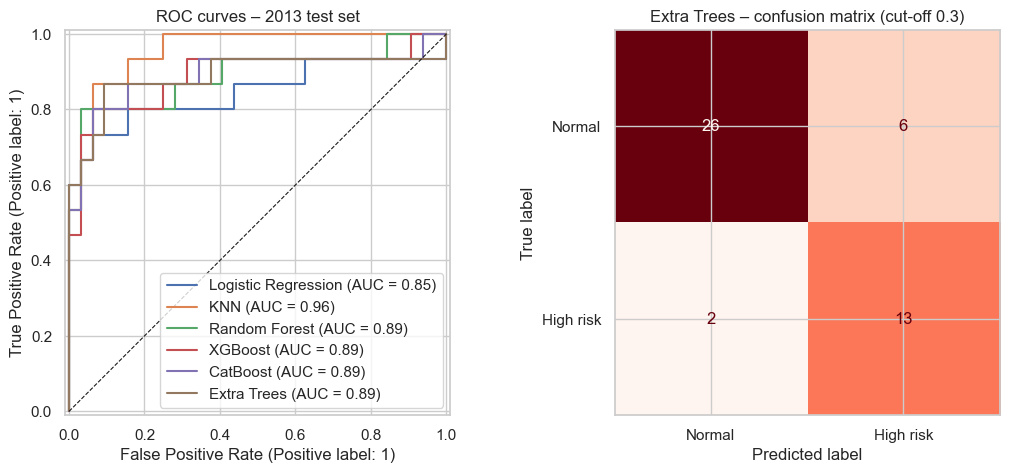

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in ["Logistic Regression", "KNN", "Random Forest", "XGBoost", "CatBoost", BEST_NAME]:
    RocCurveDisplay.from_predictions(y_test, tuned[name].predict_proba(X_test)[:, 1], name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_title("ROC curves – 2013 test set")
best_prob = best_model.predict_proba(X_test)[:, 1]
ConfusionMatrixDisplay(confusion_matrix(y_test, best_prob >= DECISION_CUTOFF),
                       display_labels=["Normal", "High risk"]).plot(ax=axes[1], cmap="Reds", colorbar=False)
axes[1].set_title(f"{BEST_NAME} – confusion matrix (cut-off {DECISION_CUTOFF})")
savefig("06_roc_confusion")
plt.show()

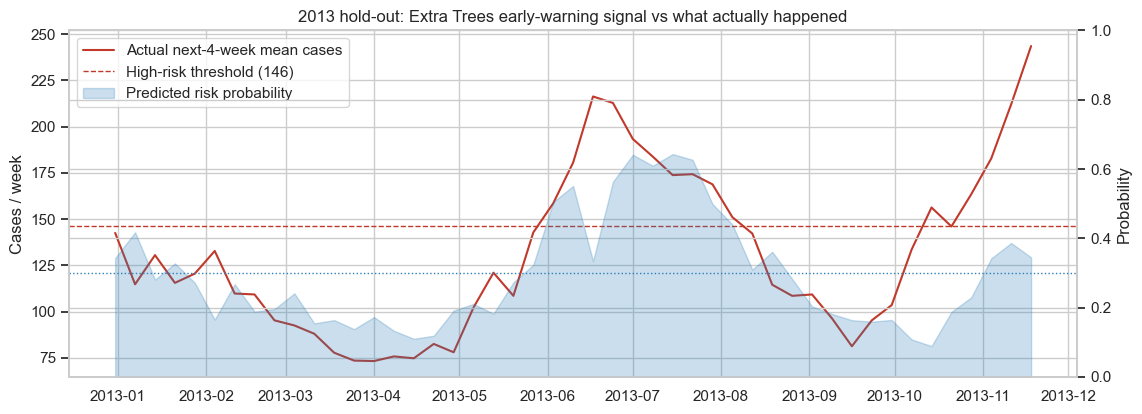

In [23]:
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.plot(test.index, test["future_mean_cases"], color="#c0392b", label="Actual next-4-week mean cases")
ax1.axhline(THRESHOLD, color="#c0392b", ls="--", lw=1, label=f"High-risk threshold ({THRESHOLD:.0f})")
ax1.set_ylabel("Cases / week")
ax2 = ax1.twinx()
ax2.fill_between(test.index, best_prob, alpha=0.25, color="#2c7fb8", label="Predicted risk probability")
ax2.axhline(DECISION_CUTOFF, color="#2c7fb8", ls=":", lw=1)
ax2.set_ylim(0, 1)
ax2.set_ylabel("Probability")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
ax1.set_title(f"2013 hold-out: {BEST_NAME} early-warning signal vs what actually happened")
savefig("07_test_timeline")
plt.show()

## 7. Explainability
### 7.1 SHAP (global and local)
SHAP (SHapley Additive exPlanations) splits every prediction into contributions from each feature,
based on cooperative game theory. We explain the **selected model** on the test weeks.

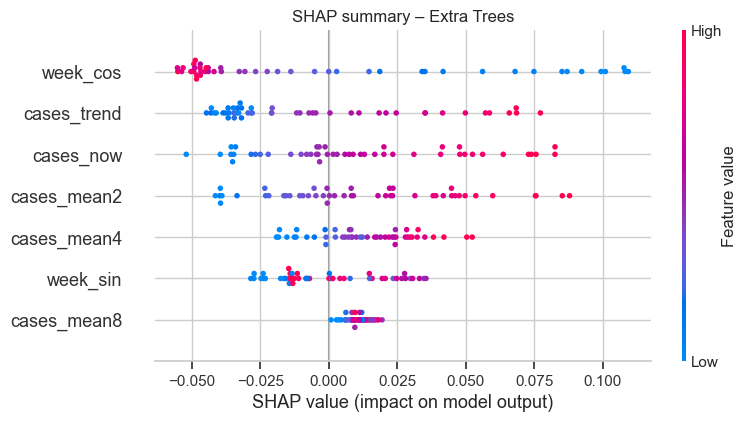

In [24]:
import shap

preprocess = best_model[:-1]
final_estimator = best_model.named_steps["model"]
Xtr_t = pd.DataFrame(preprocess.transform(X_train), columns=SELECTED, index=X_train.index)
Xte_t = pd.DataFrame(preprocess.transform(X_test), columns=SELECTED, index=X_test.index)

if BEST_NAME in ["Random Forest", "Extra Trees", "Gradient Boosting", "XGBoost", "LightGBM", "CatBoost"]:
    explainer = shap.TreeExplainer(final_estimator)
    sv = explainer(Xte_t)
    if sv.values.ndim == 3:  # sklearn forests return one set of values per class
        sv = sv[:, :, 1]
else:  # model-agnostic explainer for stacking / AdaBoost
    explainer = shap.Explainer(lambda a: final_estimator.predict_proba(a)[:, 1],
                               shap.maskers.Independent(Xtr_t, max_samples=100), seed=SEED)
    sv = explainer(Xte_t)

# Show feature values in their original (unscaled) units in the plots
sv_display = shap.Explanation(values=sv.values, base_values=sv.base_values,
                              data=X_test[SELECTED].values, feature_names=SELECTED)

shap.plots.beeswarm(sv_display, max_display=len(SELECTED), show=False)
plt.title(f"SHAP summary – {BEST_NAME}")
savefig("08_shap_beeswarm")
plt.show()

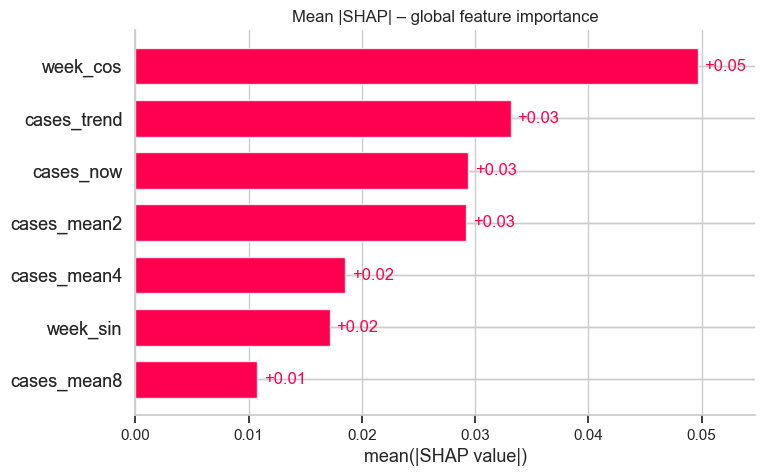

In [25]:
shap.plots.bar(sv_display, max_display=len(SELECTED), show=False)
plt.title("Mean |SHAP| – global feature importance")
savefig("09_shap_bar")
plt.show()

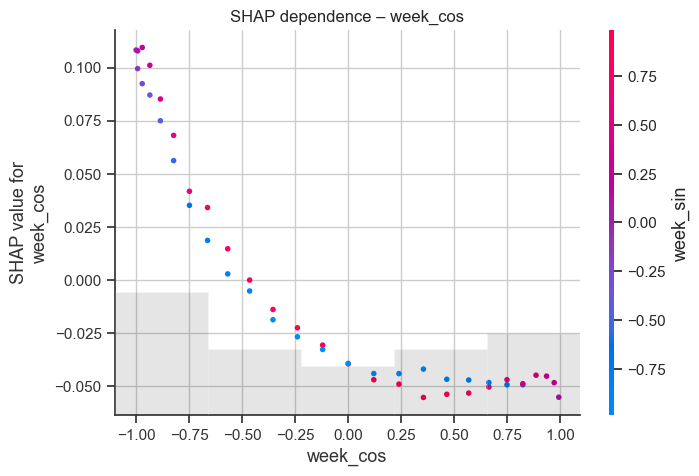

In [26]:
top_feature = SELECTED[int(np.abs(sv.values).mean(0).argmax())]
shap.plots.scatter(sv_display[:, top_feature], color=sv_display, show=False)
plt.title(f"SHAP dependence – {top_feature}")
savefig("10_shap_dependence")
plt.show()

Week of 2013-07-15: predicted risk 0.64, actual next-4-week mean = 174 cases


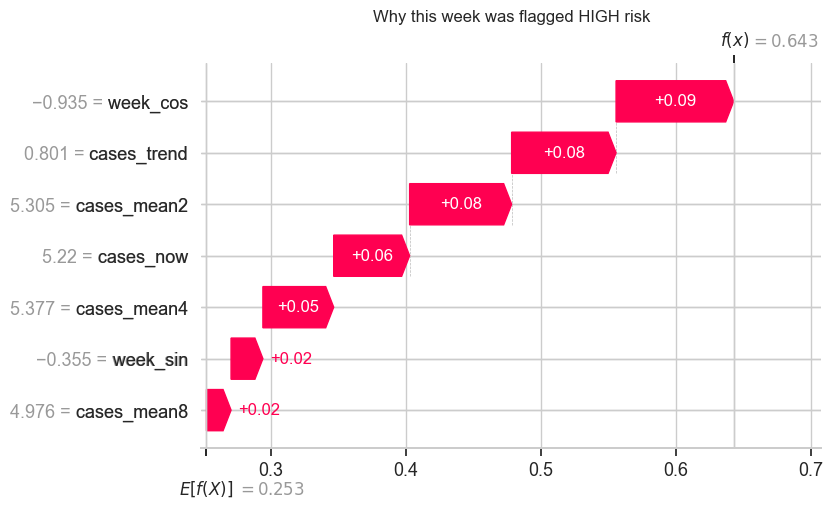

In [27]:
# Local explanation: the test week with the highest predicted risk
i_high = int(np.argmax(best_prob))
print(f"Week of {X_test.index[i_high].date()}: predicted risk {best_prob[i_high]:.2f}, "
      f"actual next-4-week mean = {test['future_mean_cases'].iloc[i_high]:.0f} cases")
shap.plots.waterfall(sv_display[i_high], max_display=10, show=False)
plt.title("Why this week was flagged HIGH risk")
savefig("11_shap_waterfall_high")
plt.show()

Week of 2013-10-14: predicted risk 0.09, actual next-4-week mean = 156 cases


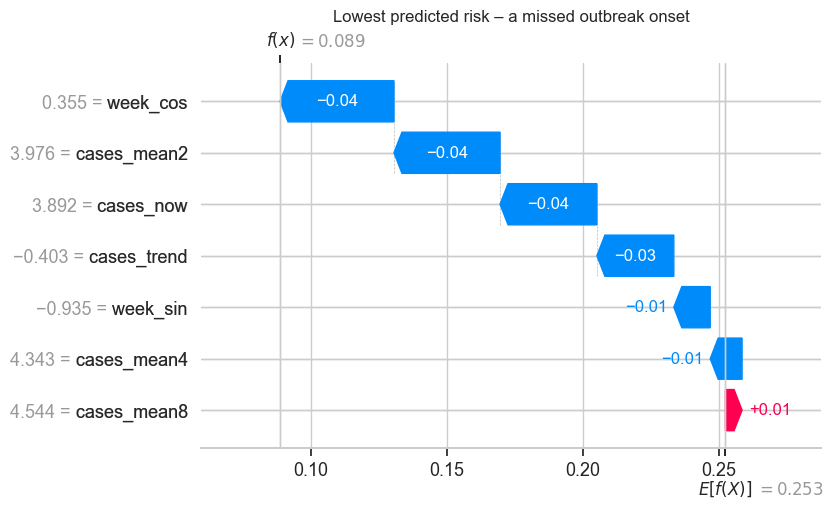

In [28]:
i_low = int(np.argmin(best_prob))
print(f"Week of {X_test.index[i_low].date()}: predicted risk {best_prob[i_low]:.2f}, "
      f"actual next-4-week mean = {test['future_mean_cases'].iloc[i_low]:.0f} cases")
shap.plots.waterfall(sv_display[i_low], max_display=10, show=False)
plt.title("Lowest predicted risk – a missed outbreak onset")
savefig("12_shap_waterfall_low")
plt.show()

**An instructive failure.** The week with the *lowest* predicted risk (mid-October 2013) was actually
followed by a high-risk month: the late-year outbreak started from a low base (about 50 cases a week, with a
falling trend). Every case feature pushed the risk down, so the model had no signal yet. The model is good at
recognising an outbreak **once momentum starts**, but it cannot foresee a sudden onset from a quiet
period. This is a key limitation (see section 10).

### 7.2 Partial Dependence Plots (PDP)
A PDP shows how the **average** predicted risk changes when one feature is varied while the others keep
their observed values. SHAP explains individual predictions; PDP shows the overall shape of each learned
relationship (rising, falling, threshold-like).

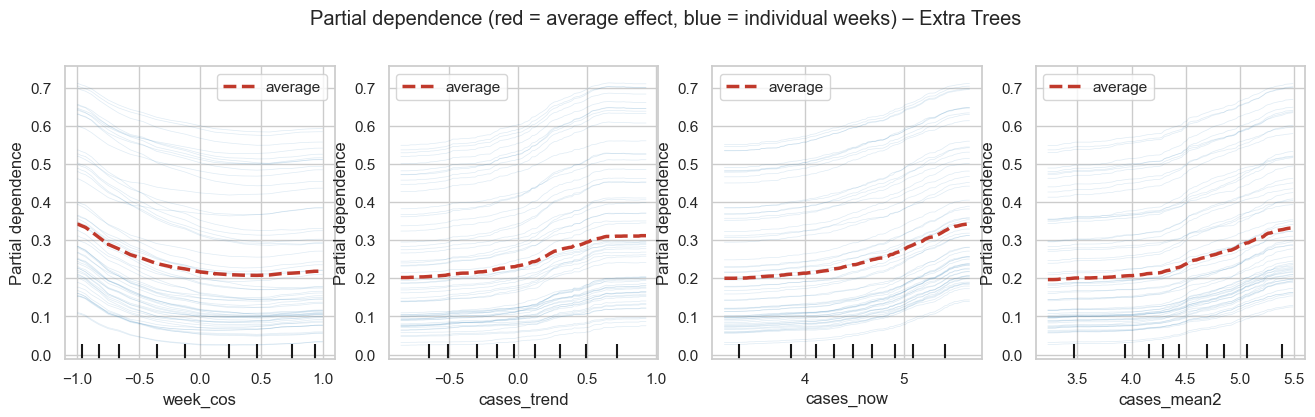

In [29]:
from sklearn.inspection import PartialDependenceDisplay

pdp_features = list(pd.Series(np.abs(sv.values).mean(0), index=SELECTED).sort_values(ascending=False).index[:4])
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
PartialDependenceDisplay.from_estimator(best_model, X_train, pdp_features, kind="both", ax=ax,
                                        subsample=60, random_state=SEED,
                                        pd_line_kw={"color": "#c0392b", "lw": 2.5},
                                        ice_lines_kw={"color": "#2c7fb8", "alpha": 0.15})
fig.suptitle(f"Partial dependence (red = average effect, blue = individual weeks) – {BEST_NAME}", y=1.03)
savefig("14_pdp")
plt.show()

### 7.3 LIME (local)
LIME explains a single prediction by fitting a simple linear model to perturbed copies of that one data
point. We use it to check that SHAP's local explanations hold up under a different method.

*Reading the conditions:* case features are on the log scale, so `cases_now > 5.0` means more than
e^5 − 1 ≈ 147 cases this week, and `4.0` ≈ 54 cases. `cases_trend > 0.4` means the last 4 weeks are about
50 % higher than the 4 weeks before.

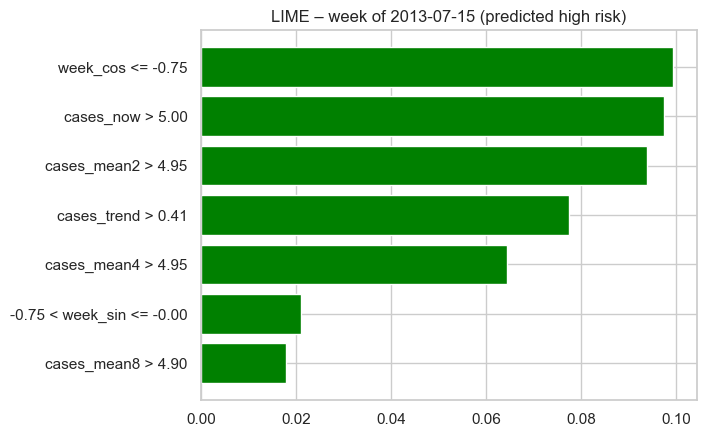

                condition  weight
        week_cos <= -0.75   0.099
         cases_now > 5.00   0.097
       cases_mean2 > 4.95   0.094
       cases_trend > 0.41   0.077
       cases_mean4 > 4.95   0.064
-0.75 < week_sin <= -0.00   0.021
       cases_mean8 > 4.90   0.018


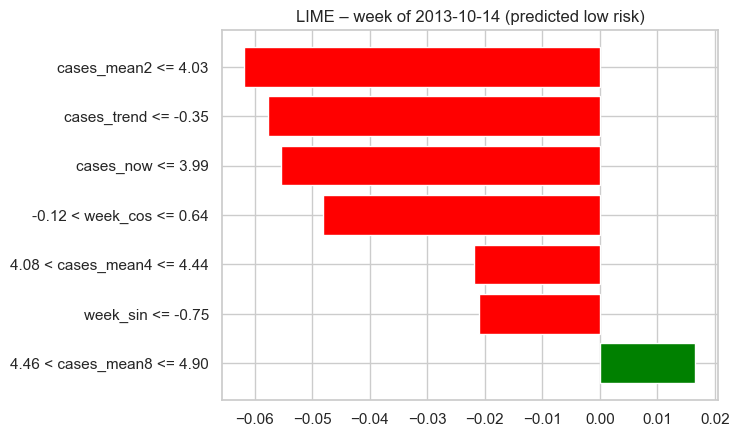

                 condition  weight
       cases_mean2 <= 4.03  -0.062
      cases_trend <= -0.35  -0.058
         cases_now <= 3.99  -0.055
  -0.12 < week_cos <= 0.64  -0.048
4.08 < cases_mean4 <= 4.44  -0.022
         week_sin <= -0.75  -0.021
4.46 < cases_mean8 <= 4.90   0.017


In [30]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(X_train[SELECTED].values, feature_names=SELECTED,
                                      class_names=["Normal", "High risk"], mode="classification",
                                      discretize_continuous=True, random_state=SEED)


def predict_fn(arr):
    return best_model.predict_proba(pd.DataFrame(arr, columns=SELECTED).reindex(columns=FEATURES))


for i, label in [(i_high, "high"), (i_low, "low")]:
    exp = lime_explainer.explain_instance(X_test[SELECTED].iloc[i].values, predict_fn, num_features=8)
    fig = exp.as_pyplot_figure(label=1)
    plt.title(f"LIME – week of {X_test.index[i].date()} (predicted {label} risk)")
    savefig(f"13_lime_{label}")
    plt.show()
    print(pd.DataFrame(exp.as_list(label=1), columns=["condition", "weight"]).round(3).to_string(index=False))

### 7.4 What the model has learned, and does it agree with domain knowledge?
| Finding (SHAP, PDP, LIME) | Domain knowledge | Agrees? |
|---|---|---|
| **Season (`week_cos`) is the most influential feature.** Risk is highest when `week_cos` ≈ −1, i.e. around weeks 20–32 (mid-May to early August). | Colombo's main dengue peak follows the **south-west monsoon (May–September)**: rain fills containers and drains, *Aedes aegypti/albopictus* breed, and cases peak about 4–8 weeks later. | ✅ Yes |
| **Rising trend** (last 4 weeks vs previous 4) increases risk. Above about +0.6 (≈ 80 % growth) the effect levels off. | Epidemics grow exponentially at the start: a rising trend means transmission is already accelerating. | ✅ Yes |
| **Current and 2-week case levels** increase risk monotonically (PDP curves rise smoothly, with no strange jumps). | More infected people → more mosquitoes become infected → more transmission (person–mosquito–person cycle). | ✅ Yes |
| **8-week average** matters little. | Old cases say little about current transmission, since the virus cycle is about 2–3 weeks. | ✅ Yes |
| **Weather adds no predictive power** once case history is known (section 4.3). | Rainfall and temperature drive dengue, but with a 5–10 week delay (section 3). By the time we predict, their effect is **already visible in recent case counts**, so the case features carry this information. | ✅ Consistent |
| The model **misses outbreak onsets from a low base** (October 2013). | The north-east monsoon (October–January) causes a second, less regular peak, and serotype shifts can trigger outbreaks without warning in case counts. | ⚠️ Known limitation |

SHAP, PDP and LIME give the **same picture**. Three different methods agreeing makes us more confident that
the explanation reflects what the model really does.

## 8. Save the model
The whole pipeline (column selection → imputation → winsorisation → scaling → model) is saved as **one
object**, together with the threshold and decision cut-off, so the app applies exactly the same
pre-processing as training.

In [31]:
bundle = {
    "model": best_model,  # exactly the model evaluated above (trained on 2009-2012)
    "model_name": BEST_NAME,
    "features": FEATURES,
    "selected_features": SELECTED,
    "feature_set": SELECTED_SET,
    "high_risk_threshold": THRESHOLD,
    "decision_cutoff": DECISION_CUTOFF,
    "horizon_weeks": HORIZON,
    "test_metrics": test_table.loc[BEST_NAME].round(3).to_dict(),
    "trained_on": f"{X_train.index.min().date()} to {X_train.index.max().date()}",
}
joblib.dump(bundle, ROOT / "models" / "dengue_alert_model.joblib")
test_table.round(3).to_csv(ROOT / "reports" / "test_results.csv")
cv_table.round(3).to_csv(ROOT / "reports" / "cv_results.csv", index=False)
print("Saved:", ROOT / "models" / "dengue_alert_model.joblib")

Saved: D:\Isuru\MSc\Applied Machine Learning\Assignment 2\models\dengue_alert_model.joblib


## 9. Inference on a new data point
We load the saved model and predict for a **new** situation: the 8 most recent weeks of case counts
and weather, as an MOH officer would type them into the app.

In [32]:
from src.data_prep import features_from_history

loaded = joblib.load(ROOT / "models" / "dengue_alert_model.joblib")

new_cases = [95, 110, 102, 130, 145, 160, 170, 190]  # last 8 weeks, oldest first
new_weather = {
    "PP": [2.0, 4.5, 12.0, 15.3, 9.8, 6.0, 3.1, 2.2],  # mm
    "H": [78, 80, 83, 85, 84, 82, 80, 79],              # %
    "Tm": [24.5, 24.8, 25.1, 25.3, 25.4, 25.6, 25.5, 25.4],
    "TEM": [27.6, 27.8, 28.0, 28.2, 28.3, 28.4, 28.3, 28.2],
}
x_new = features_from_history(new_cases, new_weather, week=22)
p = loaded["model"].predict_proba(x_new)[0, 1]
alert = p >= loaded["decision_cutoff"]
print(f"Predicted probability of a high-risk month: {p:.2f}")
print("ALERT: HIGH dengue risk in the next 4 weeks" if alert else "Normal risk expected")
x_new

Predicted probability of a high-risk month: 0.59
ALERT: HIGH dengue risk in the next 4 weeks


,cases_now,cases_mean2,cases_mean4,cases_mean8,cases_trend,PP_lag0_3,PP_lag4_7,H_lag0_3,H_lag4_7,Tm_lag0_3,Tm_lag4_7,TEM_lag0_3,TEM_lag4_7,week_sin,week_cos
7,5.252273,5.196968,5.114737,4.905344,0.418786,1.724899,2.039869,81.25,81.5,25.475,24.925,28.3,27.9,0.464723,-0.885456


## 10. Critical discussion
### 10.1 Limitations of the model
* **Small data:** 245 usable weeks (198 for training, 47 for testing) from one district. Two validation folds
  and one test year mean every metric has wide uncertainty: one extra correct week moves recall by ~7 points.
* **Cannot foresee onsets from a low base** (October 2013). It mainly detects outbreaks that have started.
* **Old data (2009–2013).** Dengue in Sri Lanka changed later (the record 2017 epidemic with the DENV-2
  serotype, urbanisation). The model must be retrained on recent data before real use.
* **Fixed threshold** (146 cases/week) from 2009–2012. Population growth and better reporting would change
  what "high" means.

### 10.2 Data-quality issues
* Found and handled: an Excel `#DIV/0!` value, 5 false zero-case weeks, 2 missing weeks, and synthetic
  2014 weather (excluded). Interpolated weeks are estimates, not observations.
* **Notified cases ≠ true infections.** Many mild or asymptomatic infections are never reported, and
  reporting depends on hospital workload and holidays. The model predicts *notifications*.
* Weather comes from a single station and may not represent the whole district.

### 10.3 Risks of bias or unfairness
* **Reporting bias:** areas with better hospital access report more completely. A model trained on
  notifications can under-estimate risk in under-served communities (e.g. low-income urban settlements),
  where dengue is often worst. If resources follow the predictions, those areas could receive less help.
* **Geographic bias:** trained only on Colombo. It should **not** be applied to other districts (e.g.
  rural or dry-zone areas) without retraining and validation.
* **Error asymmetry:** the cut-off favours recall (catching outbreaks) over precision. This is a deliberate
  value judgement: a false alarm costs a campaign, a missed outbreak costs health.

### 10.4 Real-world impact and ethical considerations
* **Positive impact:** a 4-week warning lets MOH offices schedule fogging, clean-up drives and school
  programmes, and prepare hospital beds *before* the peak.
* **Ethical data use:** the dataset contains only **aggregated weekly counts for the whole district** and
  public weather data, with no personal or identifiable information. It is publicly released for research,
  so individual consent is not required.
* **Human in the loop:** the tool is **decision support**, not an automatic decision maker. Alerts should
  be reviewed by epidemiologists together with field reports. The SHAP explanation in the app shows *why*
  an alert was raised, which supports accountability.
* **Alert fatigue:** about 1 in 3 alerts was a false alarm in 2013. Too many false alarms can make staff
  ignore warnings, so the cut-off should be reviewed with users.

## 11. Conclusions
* Using real surveillance data from the Sri Lankan Epidemiology Unit, we built an early-warning model
  that flags high-dengue months in Colombo **4 weeks ahead**.
* Careful data understanding mattered: an Excel error, false zero-case weeks, missing weeks and a year of
  synthetic weather were found and handled. Using them unchecked would have biased the model.
* The proposed algorithm, **Extra Trees** (not covered in lectures), matched the best taught algorithms on
  ROC-AUC (0.89) and on the unseen 2013 year achieved the joint-highest recall (13 of 15 high-risk weeks) and the
  highest balanced accuracy (0.84), against recall 0.40 for the naive rule.
* SHAP, PDP and LIME agree that **season, case momentum and current case levels** drive predictions, in line
  with dengue epidemiology. Weather adds little *once recent cases are known*.

**Future work:** more recent data and more districts (Gampaha, Kandy), MOH-level data, rainfall
*forecasts* to anticipate onsets, public holidays and school terms, and monthly retraining.